# 05 · Resultado: el dataset del Tema 1

Paso 5 y último de la descarga completa ([plan de la descarga](../../../docs/fase2/mercados_series/PLAN_DESCARGA.md)).
Es la **foto final** de lo que tenemos; el proceso está en los notebooks anteriores:
[01 · sonda](01_resumen_sonda.ipynb), [02 · inventario](02_inventario.ipynb),
[03 · selección y EDA](03_seleccion_eda.ipynb) y [04 · preprocesado](04_preprocesado.ipynb).

**En una frase:** un dataset de **series macro y financieras** y de **precios** con la **fecha en que cada dato se
pudo ver** (nunca antes), limpio de duplicados y de relleno, cortado en una fecha común y listo para que los agentes y
el backtest lo pidan con las tools en modo curado (`base='curada'`).

Este notebook lee tablas de metadatos del repo, los YAML, el manifiesto y, de la base curada (en `D:`), solo columnas
de **fechas y metadatos** (`serie`, `fecha_referencia`, `vintage`, `fecha_publicacion`, `metodo_publicacion`,
`fuente`) para agregarlas. **No muestra ningún valor de serie ni precio**, y todas las cifras salen de las celdas.

**Vocabulario mínimo** (el detalle, en el 03 y el 04):

- **Base curada**: las series que se quedan, con fechas de publicación prudentes; es lo que leen los agentes. La
  **base de trabajo** es la completa, con las fechas originales.
- **Fecha de publicación**: el día en que un dato se pudo ver. Si no se puede medir, se usa la **más tardía
  plausible** (regla conservadora, **E4**); si la regla de una fuente adelantaba, se retrasa en ese tramo (**tramo
  conservador**, **E5**). Las fechas solo se retrasan, nunca se adelantan.
- **Vintage**: cada versión publicada de un dato; ALFRED (el archivo de FRED) guarda las antiguas.
- **Alias**: serie que repite a otra; pedirla sirve su **canónico**. **Proyecciones**: previsiones (del FMI y de la
  Fed), en una tabla aparte.
- **Corte G2**: fecha final común del dataset; nada publicado después entra.
- **Relleno**: velas y aperturas que Yahoo inventa repitiendo el cierre; en los precios curados se quitan o pasan a nulo.
  Importa porque la decisión de t se **ejecuta a la apertura de t+1**.
- **Tramo** del S&P 500: el periodo en que un valor fue miembro del índice; los **días-tramo** suman todos los tramos.
  Lo que falta es **sesgo de supervivencia**: las empresas que salieron y dejaron de cotizar no están en Yahoo.
- **Limitación declarada**: lo que no tiene fuente gratuita y legal (F3: solo Yahoo para precios) y se documenta.
- **D1–D10, E1–E7, F1–F5, G1–G7**: las decisiones del plan por paso (2, 3, cierre del 3 y 3b).
- **UCITS**: fondos cotizados que puede comprar un inversor minorista de la UE.

> **Saneado (2026-11-21).** Esta foto es la del dataset **después** del saneado de la auditoría (35 pendientes; detalle en [`AUDITORIA_SANEADO.md`](../../../docs/fase2/mercados_series/AUDITORIA_SANEADO.md)): sin el WEO, sin los tickers reutilizados, con los saltos de precio corregidos, los huecos cortos rellenados y las tools leyendo la base curada por defecto.


In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ['png']
import hashlib
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
import yaml
from IPython.display import Markdown, display
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch

from ingesta.comun.rutas import corpus_dir, resultados_dir
from ingesta.mercados_series import catalogo, preprocesado, tools

plt.rcParams.update({'figure.dpi': 80, 'savefig.dpi': 80, 'font.size': 9, 'axes.titlesize': 11,
                     'axes.titleweight': 'bold', 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white'})
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_colwidth', 110)

# Paleta del 03 y el 04
COL_DEC = {'queda': '#2b8a3e', 'alias': '#74c0fc', 'proyecciones': '#b197fc', 'fuera': '#ced4da'}
COL_TRATO = {'entra sin aviso': '#2b8a3e', 'entra con tramo conservador (E5)': '#ffa94d',
             'entra con aviso y regla conservadora (E4)': '#d9480f'}
COL_OK, COL_MAL, COL_NA = '#2b8a3e', '#e03131', '#adb5bd'
COL_LIM = '#adb5bd'
COL_LIM_R = '#e9ecef'                                  # limitación declarada en gris rayado, como en el 03 y el 04
CMAP_INC = 'YlOrRd'


def es(x, d=0):
    # número en formato español: 1.434 · 0,95
    s = f'{x:,.{d}f}'
    return s.replace(',', '§').replace('.', ',').replace('§', '.')


def tarjetas(items, filas, cols, titulo, alto=3.3):
    # cuadrícula de tarjetas (cifra, etiqueta, subtítulo, color), como en el 03 y el 04
    fig, axs = plt.subplots(filas, cols, figsize=(12.5, alto), gridspec_kw={'wspace': .06, 'hspace': .12})
    for ax in np.ravel(axs):
        ax.axis('off')
    for ax, (cifra, etq, sub, color) in zip(np.ravel(axs), items):
        ax.add_patch(plt.Rectangle((0, 0), 1, 1, fc='#f8f9fa', ec='#dee2e6', transform=ax.transAxes))
        ax.add_patch(plt.Rectangle((0, 0), .035, 1, fc=color, ec='none', transform=ax.transAxes))
        ax.text(.1, .66, cifra, fontsize=18, fontweight='bold', color='#212529', va='center', transform=ax.transAxes)
        ax.text(.1, .36, etq, fontsize=9.5, fontweight='bold', color='#495057', va='center', transform=ax.transAxes)
        ax.text(.1, .15, sub, fontsize=7.5, color='#495057', va='center', transform=ax.transAxes)
    fig.suptitle(titulo, fontweight='bold', x=.01, ha='left')
    fig.subplots_adjust(left=.01, right=.99, top=.86, bottom=.02)
    plt.show()


def mapa(ax, datos, filas, cols, cmap=CMAP_INC):
    # mapa de calor de recuentos en escala log, con el número en cada celda (como en el 03)
    im = ax.imshow(np.where(datos > 0, datos, np.nan), cmap=cmap, norm=LogNorm(vmin=1, vmax=max(datos.max(), 2)),
                   aspect='auto')
    for i in range(datos.shape[0]):
        for j in range(datos.shape[1]):
            if datos[i, j] > 0:
                ax.text(j, i, int(datos[i, j]), ha='center', va='center', fontsize=8,
                        color='white' if np.log(datos[i, j]) > .65 * np.log(max(datos.max(), 2)) else 'black')
    ax.set_xticks(range(len(cols)), cols, fontsize=8)
    ax.set_yticks(range(len(filas)), filas, fontsize=8)
    for s in ax.spines.values():
        s.set_visible(False)
    return im


T = resultados_dir('mercados_series') / 'tablas'
SERIES_DIR = corpus_dir('mercados_series') / 'series'
REPO = Path(preprocesado.RUTA_LISTA).resolve().parents[4]
cur = pd.read_csv(T / 'curada_resumen.csv')
ver_s = pd.read_csv(T / 'curada_verificaciones.csv')
pcr = pd.read_csv(T / 'precios_curados_resumen.csv', dtype={'ticker': str})
pav = pd.read_csv(T / 'precios_curados_avisos.csv', dtype={'ticker': str})
ver_p = pd.read_csv(T / 'precios_curados_verificaciones.csv')
est = pd.read_csv(T / 'descargas_3b_estado.csv')
sp5 = pd.read_csv(T / 'sp500_cobertura_3b1.csv').rename(columns={'valor': 'dato'})
inv = pd.read_csv(T / 'inventario_series.csv')
invp = pd.read_csv(T / 'inventario_precios.csv', dtype={'ticker': str})
sel = pd.read_csv(T / 'seleccion_series.csv')
selp = pd.read_csv(T / 'seleccion_precios.csv', dtype={'id': str})
LISTA_YAML = yaml.safe_load(preprocesado.RUTA_LISTA.read_text(encoding='utf-8'))
LISTA, LISTA_P = LISTA_YAML['series'], {str(k): v for k, v in LISTA_YAML['precios'].items()}
MAN = json.loads((SERIES_DIR / 'curada_manifiesto.json').read_text(encoding='utf-8'))
R = MAN['resumen']
CORTE = pd.Timestamp(MAN['corte_g2'])
CAT = catalogo.cargar_catalogo()
n = lambda m: int(np.sum(m))

dec = pd.Series({k: v['decision'] for k, v in LISTA.items()})
dec_p = pd.Series({k: v['decision'] for k, v in LISTA_P.items()})
assert set(cur['serie']) == set(dec[dec == 'queda'].index) and len(cur) == R['series_curada']
assert set(pcr['ticker']) == set(dec_p[dec_p == 'queda'].index)
S = cur.merge(inv[['id', 'nombre', 'fuente', 'frecuencia', 'pais_zona', 'unidad', 'n_vintages']], left_on='serie',
              right_on='id', how='left').drop(columns='id')
# Series nuevas del saneado (fred:DEXTAUS, fred:DEXCHUS) que el inventario del paso 2 no tiene: del catálogo.
_cat = catalogo.cargar_catalogo()
for _c in ('nombre', 'fuente', 'frecuencia', 'unidad'):
    S[_c] = S[_c].fillna(S['serie'].map(lambda s: (_cat.get(s) or {}).get(_c)))
assert S['fuente'].notna().all()
print(f"Base curada: {es(R['filas_curada'])} filas de {len(S)} series (corte {CORTE.date()}); precios curados: "
      f"{es(len(pcr))} tickers. Lista curada, tablas y manifiesto cuadran.")

Base curada: 10.212.510 filas de 514 series (corte 2026-11-13); precios curados: 1.494 tickers. Lista curada, tablas y manifiesto cuadran.


## 0. Resumen ejecutivo

**Qué se ve:** diez cifras del dataset final, cinco conclusiones y una línea por paso del proceso. **Conclusión:** el
Tema 1 tiene un dataset completo para la Fase 2, con la fecha de publicación de cada dato y sus limitaciones
declaradas.

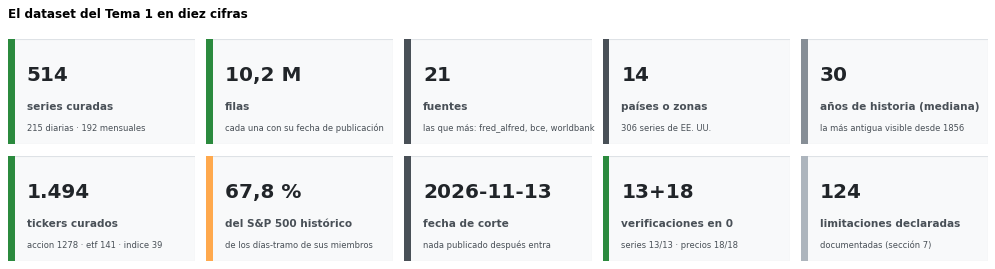

In [2]:
# Zona de cada serie: pais_zona del inventario, normalizado; sin país, por el prefijo del id
PAIS = {'USA': 'EE. UU.', 'US': 'EE. UU.', 'EA': 'zona euro', 'EA20': 'zona euro', 'XM': 'zona euro',
        '163': 'zona euro', 'EMU': 'zona euro', 'U2': 'zona euro', 'G4E': 'zona euro', 'EU27_2020': 'UE-27',
        'DEU': 'Alemania', 'DE': 'Alemania', 'FRA': 'Francia', 'FR': 'Francia', 'ITA': 'Italia', 'IT': 'Italia',
        'GBR': 'Reino Unido', 'GB': 'Reino Unido', 'UK': 'Reino Unido', 'JPN': 'Japón', 'JP': 'Japón',
        'CAN': 'Canadá', 'CA': 'Canadá', 'CHN': 'China', 'CN': 'China', '001': 'mundo', 'WLD': 'mundo',
        '200': 'emergentes', 'LMY': 'emergentes', 'AUS': 'Australia'}


def pais(fila):
    if pd.notna(fila['pais_zona']):
        return PAIS.get(str(fila['pais_zona']), str(fila['pais_zona']))
    if fila['serie'].startswith('ecb:'):
        return 'zona euro'
    return 'EE. UU.' if re.match(r'^(fred|yf|ff|gw|shiller|deriv|ofr|ust|philly):', fila['serie']) else 'otros'


ZONA = {'EE. UU.': 'EE. UU.', 'zona euro': 'zona euro y UE', 'UE-27': 'zona euro y UE', 'China': 'China',
        'mundo': 'mundo y emergentes', 'emergentes': 'mundo y emergentes'}
S['pais'] = S.apply(pais, axis=1)
S['zona'] = S['pais'].map(ZONA).fillna(S['pais'].map(lambda p: 'resto del G7' if p in
            ('Alemania', 'Francia', 'Italia', 'Reino Unido', 'Japón', 'Canadá') else 'otros'))
S['desde'] = pd.to_datetime(S['desde'])
S['pub_desde'] = pd.to_datetime(S['publicada_desde'])
S['pub_hasta'] = pd.to_datetime(S['publicada_hasta'])
anios = (S['pub_hasta'] - S['pub_desde']).dt.days / 365.25
CLASE_P = pcr['ticker'].map(lambda t: LISTA_P[t].get('clase') or 'otro')
cls = CLASE_P.value_counts()
m5 = sp5.set_index('metrica')['dato']
ok_s, ok_p, na_p = n(ver_s['filas_fallan'] == 0), n(ver_p['estado'] == 'ok'), n(ver_p['estado'] == 'no aplica')
TARJ = [
    (es(len(S)), 'series curadas', f"{n(S['frecuencia'] == 'diaria')} diarias · {n(S['frecuencia'] == 'mensual')} mensuales",
     COL_DEC['queda']),
    (f"{es(R['filas_curada'] / 1e6, 1)} M", 'filas', 'cada una con su fecha de publicación', COL_DEC['queda']),
    (es(S['fuente'].nunique()), 'fuentes', 'las que más: ' + ', '.join(S['fuente'].value_counts().head(3).index),
     '#495057'),
    (es(S['pais'].nunique()), 'países o zonas', f"{n(S['zona'] == 'EE. UU.')} series de EE. UU.", '#495057'),
    (es(anios.median()), 'años de historia (mediana)', f"la más antigua visible desde {S['pub_desde'].min().year}",
     '#868e96'),
    (es(len(pcr)), 'tickers curados', ' · '.join(f'{k} {v}' for k, v in cls.head(3).items()), COL_DEC['queda']),
    (f"{es(m5['pct_dias_tramo_cubiertos'], 1)} %", 'del S&P 500 histórico', 'de los días-tramo de sus miembros',
     '#ffa94d'),
    (str(CORTE.date()), 'fecha de corte', 'nada publicado después entra', '#495057'),
    (f'{ok_s}+{ok_p}', 'verificaciones en 0', f'series {ok_s}/{len(ver_s)} · precios {ok_p}/{len(ver_p) - na_p}',
     COL_OK if ok_s == len(ver_s) and ok_p == len(ver_p) - na_p else COL_MAL),
    (es(n(est['estado_3b'] == 'limitacion_declarada')), 'limitaciones declaradas', 'documentadas (sección 7)', COL_LIM),
]
tarjetas(TARJ, 2, 5, 'El dataset del Tema 1 en diez cifras')
pct_ap = 100 * (1 - pcr['aperturas_anuladas'].sum() / pcr['sesiones_despues'].sum())

In [3]:
# Sonda: las cifras que imprimió el 01 (base y precios del corpus al empezar la descarga completa)
nb01 = json.loads((REPO / 'notebooks/fase2/mercados_series/01_resumen_sonda.ipynb').read_text(encoding='utf-8'))
texto01 = '\n'.join(''.join(o.get('text', '')) for c in nb01['cells'] for o in c.get('outputs', []))
SONDA_S = int(re.search(r'([\d,]+) series', texto01).group(1).replace(',', ''))
SONDA_P = int(re.search(r'total ([\d,]+)', texto01).group(1).replace(',', ''))
e3 = est['estado_3b'].value_counts()
fallos_v = int(ver_s['filas_fallan'].sum()) + int(ver_p.loc[ver_p['estado'] != 'no aplica', 'n_fallos'].sum())
dsel = sel['decision'].value_counts()
lineas = [
    ('1 · sonda', '01_resumen_sonda', f'{es(SONDA_S)} series y {es(SONDA_P)} ficheros de precios de partida'),
    ('2 · inventario', '02_inventario', f'{es(len(inv))} series y {es(len(invp))} ficheros medidos (historia, fecha, '
     'redundancia); criterio D1–D10'),
    ('3 · selección y EDA', '03_seleccion_eda', f"quedan {es(dsel.get('queda', 0))}, alias {dsel.get('alias', 0)}, "
     f"fuera {dsel.get('fuera', 0)}, proyecciones {dsel.get('proyecciones', 0)}; plan de fechas conservadoras"),
    ('3b · descargas', '(órdenes)', f"{e3.get('hecho', 0)} hechas, {e3.get('resuelto', 0)} resueltas, "
     f"{e3.get('limitacion_declarada', 0)} limitaciones declaradas, {e3.get('parcial', 0)} parcial y "
     f"{e3.get('aplazado', 0)} aplazada"),
    ('4 · preprocesado', '04_preprocesado', f"{es(R['filas_curada'])} filas curadas; las fechas solo se retrasan; "
     f"{ok_s}+{ok_p} verificaciones en 0"),
]
display(Markdown(
    f"- **Qué es:** {len(S)} series macro y financieras de {S['fuente'].nunique()} fuentes y {S['pais'].nunique()} "
    f"países o zonas, una por concepto (los {MAN['salidas']['alias']['filas']} alias apuntan a su canónico), y "
    f"{es(len(pcr))} tickers de precios, todo cortado el {CORTE.date()}.\n"
    f"- **Nada se ve antes de tiempo:** cada fila lleva la fecha en que se pudo conocer; donde no se puede medir, la más "
    f"tardía plausible. Las {ok_s + ok_p} verificaciones dan {'0 fallos' if fallos_v == 0 else f'{fallos_v} fallos'}.\n"
    f"- **Hay historia para el backtest:** {n(S['pub_desde'] <= '2008-01-02')} series visibles desde 2007 y "
    f"{n(S['pub_desde'] <= '2001-01-02')} desde 2000 (sección 3).\n"
    f"- **Los precios sirven para ejecutar en t+1:** las aperturas de relleno están anuladas (quedan reales el "
    f"{es(pct_ap, 1)} %), pero el S&P 500 histórico solo está cubierto en un {es(m5['pct_dias_tramo_cubiertos'], 1)} % "
    "por el sesgo de supervivencia de Yahoo.\n"
    f"- **Lo que falta está declarado y lo siguiente es el catálogo:** {e3.get('limitacion_declarada', 0)} limitaciones "
    "con su motivo (sección 7); qué agente usa cada dato es aún orientativo y el catálogo formal es el paso siguiente "
    "(sección 6)."))
pd.DataFrame(lineas, columns=['paso', 'notebook', 'resultado'])

- **Qué es:** 514 series macro y financieras de 21 fuentes y 14 países o zonas, una por concepto (los 59 alias apuntan a su canónico), y 1.494 tickers de precios, todo cortado el 2026-11-13.
- **Nada se ve antes de tiempo:** cada fila lleva la fecha en que se pudo conocer; donde no se puede medir, la más tardía plausible. Las 31 verificaciones dan 0 fallos.
- **Hay historia para el backtest:** 443 series visibles desde 2007 y 350 desde 2000 (sección 3).
- **Los precios sirven para ejecutar en t+1:** las aperturas de relleno están anuladas (quedan reales el 96,1 %), pero el S&P 500 histórico solo está cubierto en un 67,8 % por el sesgo de supervivencia de Yahoo.
- **Lo que falta está declarado y lo siguiente es el catálogo:** 124 limitaciones con su motivo (sección 7); qué agente usa cada dato es aún orientativo y el catálogo formal es el paso siguiente (sección 6).

,paso,notebook,resultado
0,1 · sonda,01_resumen_sonda,1.434 series y 1.471 ficheros de precios de partida
1,2 · inventario,02_inventario,"1.521 series y 1.624 ficheros medidos (historia, fecha, redundancia); criterio D1–D10"
2,3 · selección y EDA,03_seleccion_eda,"quedan 533, alias 109, fuera 570, proyecciones 309; plan de fechas conservadoras"
3,3b · descargas,(órdenes),"48 hechas, 3 resueltas, 124 limitaciones declaradas, 1 parcial y 1 aplazada"
4,4 · preprocesado,04_preprocesado,10.212.510 filas curadas; las fechas solo se retrasan; 13+18 verificaciones en 0


## 1. De la sonda al dataset final

**Qué se ve:** cuántas series y cuántos ficheros de precios había en cada paso, y qué entró, salió o se aplazó.
**Conclusión:** las descargas del 3b añadieron series y tickers; la selección quita sobre todo lo que está fuera del
alcance, las proyecciones (que van a su tabla) y los duplicados (alias), y los precios se quedan casi enteros.

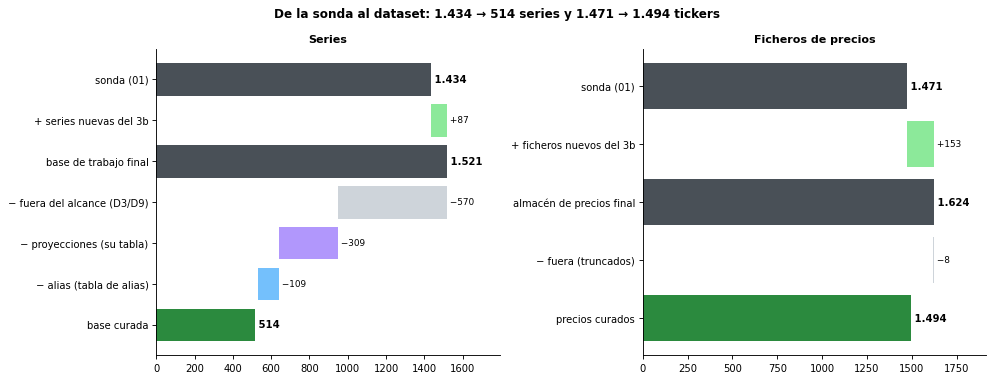

Estado final de la lista del 3b (descargas_3b_estado.csv, estado_3b):


estado_3b,aplazado,hecho,limitacion_declarada,parcial,resuelto,total
tipo,,,,,,
archivo_periodico,0,9,0,0,0,9
constituyentes,0,0,2,0,0,2
deslistado,0,0,2,0,0,2
ediciones,0,3,34,0,0,37
excepcion_refresco,0,0,24,0,0,24
fechas,0,0,1,0,3,4
limitacion_agregada,0,0,2,0,0,2
precios,1,1,5,0,0,7
redescarga,0,0,8,0,0,8


In [4]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.8))


def cascada(ax, pasos, titulo):
    nivel, ys, etqs = 0, [], []
    for i, (etq, k, tipo, color) in enumerate(pasos):
        y = len(pasos) - 1 - i
        if tipo == 'total':
            ax.barh(y, k, color=color)
            ax.text(k, y, f' {es(k)}', va='center', fontweight='bold')
            nivel = k
        else:
            izq = nivel if k >= 0 else nivel + k
            ax.barh(y, abs(k), left=izq, color=color)
            ax.text(max(nivel, nivel + k), y, f" {'+' if k >= 0 else '−'}{es(abs(k))}", va='center', fontsize=8)
            nivel += k
        etqs.append(etq)
    ax.set_yticks(range(len(pasos)), list(reversed(etqs)))
    ax.set_title(titulo, fontsize=10)
    ax.set_xlim(0, max(p[1] for p in pasos) * 1.18)


base_s, base_p = len(inv), len(invp)
cascada(a1, [('sonda (01)', SONDA_S, 'total', '#495057'),
             ('+ series nuevas del 3b', base_s - SONDA_S, 'delta', '#8ce99a'),
             ('base de trabajo final', base_s, 'total', '#495057'),
             ('− fuera del alcance (D3/D9)', -n(sel['decision'] == 'fuera'), 'delta', COL_DEC['fuera']),
             ('− proyecciones (su tabla)', -n(sel['decision'] == 'proyecciones'), 'delta', COL_DEC['proyecciones']),
             ('− alias (tabla de alias)', -n(sel['decision'] == 'alias'), 'delta', COL_DEC['alias']),
             ('base curada', len(S), 'total', COL_DEC['queda'])], 'Series')
cascada(a2, [('sonda (01)', SONDA_P, 'total', '#495057'),
             ('+ ficheros nuevos del 3b', base_p - SONDA_P, 'delta', '#8ce99a'),
             ('almacén de precios final', base_p, 'total', '#495057'),
             ('− fuera (truncados)', -n(selp['decision'] == 'fuera'), 'delta', COL_DEC['fuera']),
             ('precios curados', len(pcr), 'total', COL_DEC['queda'])], 'Ficheros de precios')
fig.suptitle(f'De la sonda al dataset: {es(SONDA_S)} → {es(len(S))} series y {es(SONDA_P)} → {es(len(pcr))} tickers',
             fontweight='bold')
plt.tight_layout()
plt.show()
print('Estado final de la lista del 3b (descargas_3b_estado.csv, estado_3b):')
pd.crosstab(est['tipo'], est['estado_3b'], margins=True, margins_name='total')

## 2. Qué tenemos, por tema económico

**Qué se ve:** las series curadas agrupadas por tema. El grupo sale de reglas por id (curvas, divisas, académicas…)
y, para las demás, del campo `grupo` del catálogo; la zona, del país del inventario. **Conclusión:** el núcleo es
EE. UU. (curvas, crédito, actividad, empleo, inflación, mercados), con la zona euro y el resto del G7 bien cubiertos en
tipos, curvas, inflación, paro y actividad, y el mundo y los emergentes solo en lo anual del FMI y el Banco Mundial.

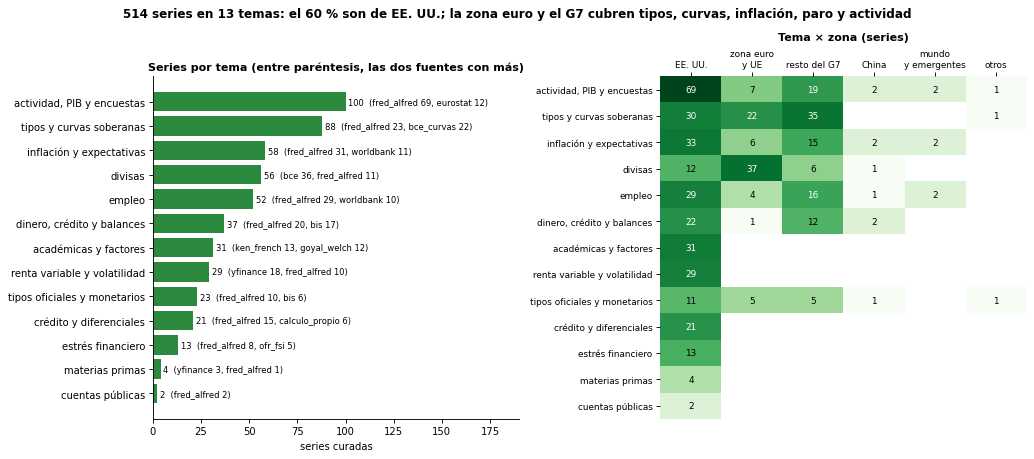

Series por fuente: fred_alfred 229, bce 44, worldbank 31, bis 31, yfinance 26, oecd 24, eurostat 22, bce_curvas 22, mof_jgb 15, ken_french 13, goyal_welch 12, boe_curvas 12, calculo_propio 7, boc_curva 6, shiller 6, ofr_fsi 5, ust_curva 3, rba 2, boc 2, bundesbank 1, boj 1


In [5]:
REGLAS_GRUPO = [
    ('académicas y factores', r'^(ff|gw|shiller):'),
    ('divisas', r'^(ecb:EXR|fred:(DEX|DTWEX|TWEX|NNUSBIS|RNUSBIS)|bis:WS_EER|yf:DX-Y)'),
    ('estrés financiero', r'^(ofr:|fred:(NFCI|ANFCI|CFSI|KCFSI|STLFSI))'),
    ('renta variable y volatilidad', r'^(yf:\^(?!IRX|FVX|TNX|TYX|BCOM|SPGSCI)|fred:(VIX|VXO|VXD|VXN|RVX|EVZ|GVZ|OVX|VXEEM|'
                                     r'VXEWZ|VXTYN)|deriv:VOLREAL)'),
    ('materias primas', r'^(yf:(GC=F|\^BCOM|\^SPGSCI)|fred:WTISPLC)'),
    ('tipos y curvas soberanas', r'^(fred:(DGS|GS\d|DTB|TB3MS|DFII|T10Y2Y|T10Y3M)|ust:|ecb:YC|boe:|mof:|boc:(BOND|BD)|bbk:|'
                                 r'rba:FCMYGBAG|yf:\^(IRX|FVX|TNX|TYX))'),
    ('tipos oficiales y monetarios', r'^(bis:WS_CBPOL|ecb:(DFR|MRO|EONIA|ESTR)|boc:V39079|boj:|rba:FIRMMCRTD|fred:(DFF|EFFR|'
                                     r'FEDFUNDS|SOFR|OBFR|IORB|DPCREDIT|LIOR3M|DED3|DCPF3M|M13002))'),
    ('crédito y diferenciales', r'^(fred:(AAA|BAA|DAAA|DBAA|BAAFFM|BAML|TEDRATE|TB3SMFFM)|deriv:)'),
    ('inflación y expectativas', r'^(eurostat:HICP|ecb:HICP|oecd:CP|fred:(T10YIE|T5YIE|T5YIFR|MICH)|imf:WEO\..*PCPIPCH|'
                                 r'wb:.*FP\.CPI)'),
    ('empleo', r'^(oecd:UNEMP|eurostat:une_rt|ecb:LFSI|imf:WEO\..*\.LUR|wb:.*SL\.UEM)'),
    ('cuentas públicas', r'^(imf:WEO\..*GGX|fred:(GFDEBTN|MTSDS133FMS))'),
    ('dinero, crédito y balances', r'^bis:WS_(CREDIT_GAP|DSR)'),
    ('actividad, PIB y encuestas', r'(namq|ei_bssi|^ecb:MNA|LI_AA|NGDP|NY\.GDP|^philly:|USRECD)'),
]
GRUPO_CAT = {'precios': 'inflación y expectativas', 'empleo': 'empleo', 'dinero_credito': 'dinero, crédito y balances',
             'estres_financiero': 'estrés financiero', 'otros': 'cuentas públicas'}


def grupo(sid):
    for nombre, patron in REGLAS_GRUPO:
        if re.search(patron, sid):
            return nombre
    g = CAT.get(sid, {}).get('grupo')
    if g:
        return GRUPO_CAT.get(g, 'actividad, PIB y encuestas')
    return 'otros'


S['grupo'] = S['serie'].map(grupo)
assert n(S['grupo'] == 'otros') == 0, S.loc[S['grupo'] == 'otros', 'serie'].tolist()
ORDEN_G = S['grupo'].value_counts().index.tolist()
top_f = S['fuente'].value_counts().head(8).index.tolist()
S['fuente_g'] = S['fuente'].where(S['fuente'].isin(top_f), 'otras')
ct = pd.crosstab(S['grupo'], S['fuente']).reindex(index=ORDEN_G[::-1], fill_value=0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.8), gridspec_kw={'width_ratios': [1, 1]})
tot_g = ct.sum(axis=1)
a1.barh(ct.index, tot_g, color=COL_DEC['queda'])
for y, (g_, k) in enumerate(tot_g.items()):
    top2 = ct.loc[g_].sort_values(ascending=False).head(2)
    a1.text(k + 1.5, y, f"{k}  ({', '.join(f'{f} {v}' for f, v in top2.items() if v)})", va='center', fontsize=7.5)
a1.set_xlim(0, tot_g.max() * 1.9)
a1.set_xlabel('series curadas')
a1.set_title('Series por tema (entre paréntesis, las dos fuentes con más)', fontsize=10)
ZONAS = ['EE. UU.', 'zona euro y UE', 'resto del G7', 'China', 'mundo y emergentes', 'otros']
hz = pd.crosstab(S['grupo'], S['zona']).reindex(index=ORDEN_G, columns=[z for z in ZONAS if z in set(S['zona'])],
                                                fill_value=0)
im = mapa(a2, hz.to_numpy().astype(float), hz.index, [z.replace(' y ', '\ny ') for z in hz.columns], cmap='Greens')
a2.xaxis.tick_top()
a2.set_title('Tema × zona (series)', pad=8, fontsize=10)
fig.suptitle(f"{len(S)} series en {S['grupo'].nunique()} temas: el {es(100 * n(S['zona'] == 'EE. UU.') / len(S))} % "
             "son de EE. UU.; la zona euro y el G7 cubren tipos, curvas, inflación, paro y actividad", fontweight='bold')
plt.tight_layout()
plt.show()
print('Series por fuente:', ', '.join(f'{f} {k}' for f, k in S['fuente'].value_counts().items()))

## 3. Cobertura temporal

**Qué se ve:** por tema, desde cuándo son visibles las series (por la fecha de publicación curada, no por la de
referencia: lo que un agente podía ver de verdad) y hasta dónde llegan, y cuántas sirven para cada ventana posible del
backtest. **Conclusión:** casi todos los temas tienen historia visible desde antes de 2007; la ventana desde 2000 se
queda sin parte de lo internacional y de los índices reconstruidos, cuya historia antigua no existía en su fecha.

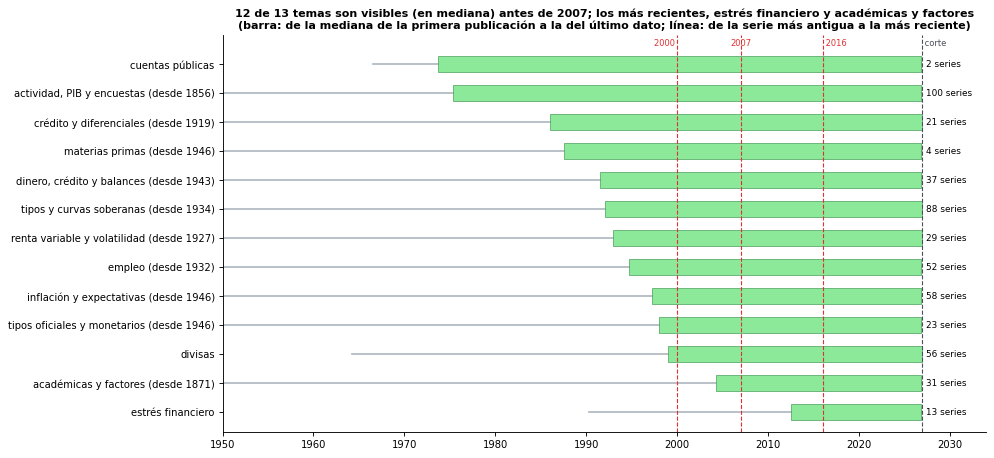

In [6]:
G = (S.groupby('grupo').agg(n=('serie', 'size'), desde_min=('pub_desde', 'min'), desde_med=('pub_desde', 'median'),
                            hasta_max=('pub_hasta', 'max'), hasta_med=('pub_hasta', 'median'))
       .sort_values('desde_med', ascending=False))
X0 = pd.Timestamp('1950-01-01')
fig, ax = plt.subplots(figsize=(12.5, 5.8))
for y, (g, r_) in enumerate(G.iterrows()):
    ax.plot([max(r_['desde_min'], X0), r_['hasta_max']], [y, y], color='#adb5bd', lw=1.5, zorder=1)
    ax.barh(y, (r_['hasta_med'] - max(r_['desde_med'], X0)).days, left=max(r_['desde_med'], X0), height=.55,
            color='#8ce99a', ec=COL_DEC['queda'], lw=.5, zorder=2)
    ax.text(pd.Timestamp('2027-06-01'), y, f"{int(r_['n'])} series", va='center', fontsize=8)
for a, etq, ha in ((pd.Timestamp('2000-01-01'), '2000 ', 'right'), (pd.Timestamp('2007-01-01'), '2007', 'center'),
                   (pd.Timestamp('2016-01-01'), ' 2016', 'left'), (CORTE, ' corte', 'left')):
    ax.axvline(a, color='#e03131' if etq.strip() != 'corte' else '#495057', ls='--', lw=1)
    ax.text(a, len(G) - .35, etq, color='#e03131' if etq.strip() != 'corte' else '#495057', fontsize=7.5, ha=ha)
ax.set_yticks(range(len(G)), [g + (f" (desde {r_['desde_min'].year})" if r_['desde_min'] < X0 else '')
                              for g, r_ in G.iterrows()])
ax.set_xlim(X0, pd.Timestamp('2034-01-01'))
ax.set_ylim(-.7, len(G))
antes07 = G[G['desde_med'] <= pd.Timestamp('2007-01-01')]
ax.set_title(f"{len(antes07)} de {len(G)} temas son visibles (en mediana) antes de 2007; los más recientes, "
             f"{' y '.join(G.index[:2])}\n(barra: de la mediana de la primera publicación a la del último dato; "
             "línea: de la serie más antigua a la más reciente)", fontsize=10)
plt.tight_layout()
plt.show()

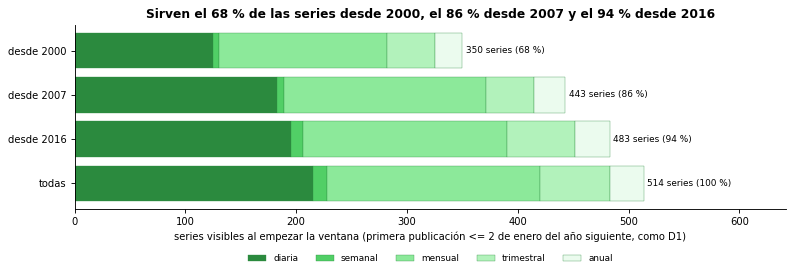

,desde 2000,desde 2007,desde 2016,todas
frecuencia,,,,
diaria,125,183,195,215
semanal,5,6,11,13
mensual,152,182,184,192
trimestral,43,44,62,63
anual,25,28,31,31


In [7]:
VENT = {'desde 2000': '2001-01-02', 'desde 2007': '2008-01-02', 'desde 2016': '2017-01-02'}
FREQ = ['diaria', 'semanal', 'mensual', 'trimestral', 'anual']
COL_FREQ = dict(zip(FREQ, ['#2b8a3e', '#51cf66', '#8ce99a', '#b2f2bb', '#ebfbee']))
vt = pd.DataFrame({v: S[S['pub_desde'] <= c].groupby('frecuencia').size() for v, c in VENT.items()}).reindex(FREQ).fillna(0)
vt['todas'] = S.groupby('frecuencia').size().reindex(FREQ)
fig, ax = plt.subplots(figsize=(10, 3.6))
izq = np.zeros(vt.shape[1])
for f in FREQ:
    ax.barh(vt.columns, vt.loc[f], left=izq, color=COL_FREQ[f], label=f, ec='#2b8a3e', lw=.3)
    izq += vt.loc[f].to_numpy()
for y, k in enumerate(vt.sum()):
    ax.text(k + 3, y, f'{int(k)} series ({es(100 * k / len(S))} %)', va='center', fontsize=8)
ax.invert_yaxis()
ax.set_xlim(0, len(S) * 1.25)
ax.set_xlabel('series visibles al empezar la ventana (primera publicación <= 2 de enero del año siguiente, como D1)')
pv = (100 * vt.sum() / len(S)).round()
ax.set_title(f"Sirven el {es(pv['desde 2000'])} % de las series desde 2000, el {es(pv['desde 2007'])} % desde 2007 y el "
             f"{es(pv['desde 2016'])} % desde 2016")
ax.legend(ncol=5, frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(.5, -.2))
plt.tight_layout()
plt.show()
vt.astype(int)

## 4. Fiabilidad de las fechas en el dataset final

**Qué se ve:** cada fila de la base curada según cómo se fechó su publicación:

- **exacta**: la fecha real, de un vintage archivado (ALFRED, ediciones de la OCDE, del archivo del WDI o los académicos) o del
  cierre del mercado;
- **regla verificada o contrastada**: un calendario de publicación medido contra la fecha real, que no adelanta;
- **regla conservadora (E4)**: no se puede medir; se usa la fecha más tardía plausible;
- **tramo conservador (E5) y H.15 antiguo**: la regla adelantaba en ese tramo; se retrasa con el mayor adelanto medido;
- **reconstruida**: índices calculados hacia atrás; antes de su creación no existían y se fechan en su creación;
- **derivada**: calculada con otras series; toma la fecha más tardía de sus componentes curados.

**Conclusión:** la mayoría de las filas tiene fecha exacta; el resto lleva una fecha que nunca adelanta a la real, y
las verificaciones lo confirman.

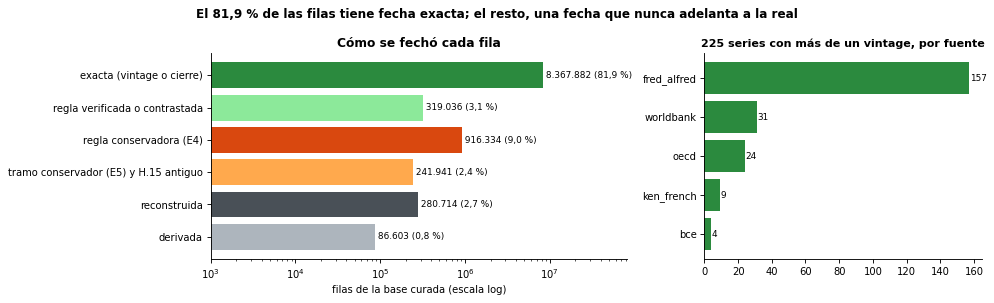

Filas: 10.212.510; con fecha exacta 81,9 %. Vintages distintos por serie con vintages: mediana 507, máximo 8.727.
Verificaciones: series 13/13 y precios 18/18 con 0 fallos; filas que adelantan su fecha: 0.


In [8]:
cols_b = ['serie', 'fecha_referencia', 'vintage', 'fecha_publicacion', 'metodo_publicacion', 'fuente']
b = pq.read_table(SERIES_DIR / 'base_curada.parquet', columns=cols_b,
                  read_dictionary=['serie', 'vintage', 'metodo_publicacion', 'fuente']).to_pandas()
assert len(b) == R['filas_curada']
reg = pq.read_table(SERIES_DIR / 'registro_cambios.parquet',
                    columns=['serie', 'fecha_referencia', 'vintage', 'seccion', 'reconstruida', 'h15', 'derivada',
                             'retraso_dias', 'en_base_curada']).to_pandas()
reg = reg[reg['en_base_curada'] & (reg['retraso_dias'] > 0)].drop(columns=['en_base_curada', 'retraso_dias'])
reg['serie'] = pd.Categorical(reg['serie'], categories=b['serie'].cat.categories)
reg['vintage'] = pd.Categorical(reg['vintage'], categories=b['vintage'].cat.categories)
b = b.merge(reg, on=['serie', 'fecha_referencia', 'vintage'], how='left')
seccion = b['serie'].map(cur.set_index('serie')['seccion']).astype(object)
met = b['metodo_publicacion'].astype(str)
TIPOS_F = ['exacta (vintage o cierre)', 'regla verificada o contrastada', 'regla conservadora (E4)',
           'tramo conservador (E5) y H.15 antiguo', 'reconstruida', 'derivada']
b['tipo_fecha'] = np.select(
    [b['reconstruida'].eq(True), b['seccion'].eq('tramo_no_fiable') | b['h15'].eq(True),
     b['seccion'].eq('reglas_conservadoras'), b['derivada'].eq(True) | met.eq('derivada'),
     met.isin(['vintage_exacto', 'cierre_mercado']), seccion.eq('reglas_conservadoras')],
    [TIPOS_F[4], TIPOS_F[3], TIPOS_F[2], TIPOS_F[5], TIPOS_F[0], TIPOS_F[2]], TIPOS_F[1])
tf = b['tipo_fecha'].value_counts().reindex(TIPOS_F).fillna(0)
COL_TF = dict(zip(TIPOS_F, [COL_OK, '#8ce99a', COL_TRATO['entra con aviso y regla conservadora (E4)'],
                            COL_TRATO['entra con tramo conservador (E5)'], '#495057', '#adb5bd']))
nv = b.groupby('serie', observed=True)['vintage'].nunique()
con_v = nv[nv > 1]
fuente_s = S.set_index('serie')['fuente']
vf = fuente_s.reindex(con_v.index).value_counts()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 3.8), gridspec_kw={'width_ratios': [1.5, 1]})
a1.barh(tf.index[::-1], tf.values[::-1], color=[COL_TF[k] for k in tf.index[::-1]])
for y, k in enumerate(tf.values[::-1]):
    a1.text(k, y, f' {es(k)} ({es(100 * k / len(b), 1)} %)', va='center', fontsize=8)
a1.set_xscale('log')
a1.set_xlim(1e3, len(b) * 8)
a1.set_xlabel('filas de la base curada (escala log)')
a1.set_title('Cómo se fechó cada fila')
a2.barh(vf.index[::-1], vf.values[::-1], color=COL_DEC['queda'])
for y, k in enumerate(vf.values[::-1]):
    a2.text(k + .5, y, str(k), va='center', fontsize=8)
a2.set_title(f'{len(con_v)} series con más de un vintage, por fuente', fontsize=10)
fig.suptitle(f"El {es(100 * tf[TIPOS_F[0]] / len(b), 1)} % de las filas tiene fecha exacta; el resto, una fecha que nunca "
             "adelanta a la real", fontweight='bold')
plt.tight_layout()
plt.show()
print(f"Filas: {es(len(b))}; con fecha exacta {es(100 * tf[TIPOS_F[0]] / len(b), 1)} %. Vintages distintos por serie "
      f"con vintages: mediana {es(con_v.median())}, máximo {es(con_v.max())}.")
print(f"Verificaciones: series {ok_s}/{len(ver_s)} y precios {ok_p}/{len(ver_p) - na_p} con 0 fallos; filas que "
      f"adelantan su fecha: {int(ver_s.set_index('verificacion').loc['no_adelanta', 'filas_fallan'])}.")
del b, reg

## 5. Precios

**Qué se ve:** los tickers curados por clase, mercado y capa del universo; la cobertura del S&P 500 histórico; las
aperturas reales frente a las anuladas; y los avisos por tipo. **Conclusión:** el grueso son acciones (S&P 500 y
grandes empresas internacionales) más el universo de ETF y UCITS de la cartera; las aperturas de relleno, que no
existieron, están anuladas para que la ejecución a la apertura de t+1 sea realista.

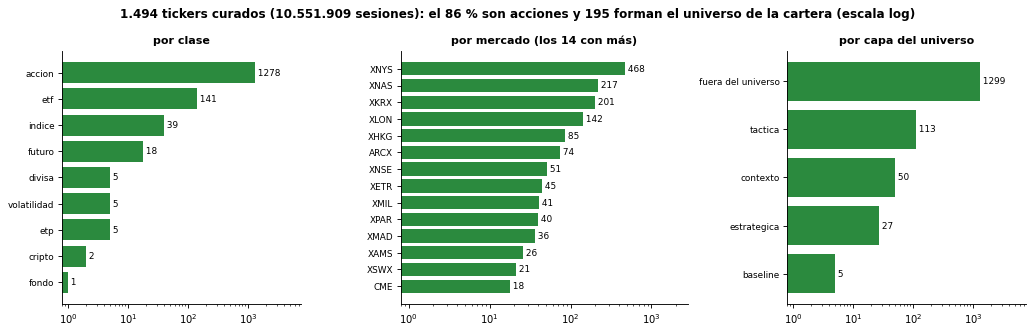

In [9]:
P = pcr.merge(invp[['ticker', 'mercado', 'capa', 'clase']], on='ticker', how='left')
P['clase'] = CLASE_P.values
P['capa'] = P['capa'].fillna('fuera del universo')
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2), gridspec_kw={'width_ratios': [1, 1.2, 1]})
for ax, col, top, tit in ((axs[0], 'clase', None, 'por clase'), (axs[1], 'mercado', 14, 'por mercado (los 14 con más)'),
                          (axs[2], 'capa', None, 'por capa del universo')):
    v = P[col].value_counts()
    v = v.head(top) if top else v
    ax.barh(v.index[::-1], v.values[::-1], color=COL_DEC['queda'])
    for y, k in enumerate(v.values[::-1]):
        ax.text(k, y, f' {k}', va='center', fontsize=8)
    ax.set_xscale('log')
    ax.set_xlim(.8, v.max() * 6)
    ax.set_title(tit, fontsize=10)
    ax.tick_params(axis='y', labelsize=8)
fig.suptitle(f"{es(len(P))} tickers curados ({es(P['sesiones_despues'].sum())} sesiones): el "
             f"{es(100 * n(P['clase'] == 'accion') / len(P))} % son acciones y {n(P['capa'] != 'fuera del universo')} "
             "forman el universo de la cartera (escala log)", fontweight='bold')
plt.tight_layout()
plt.show()

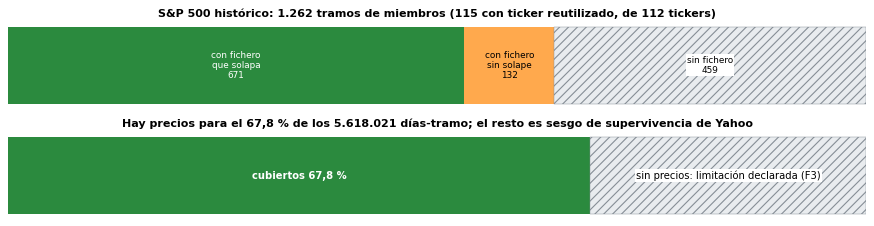

In [10]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 2.9))
partes = [('con fichero que solapa', m5['tramos_con_fichero_que_solapa'], COL_OK),
          ('con fichero sin solape', m5['tramos_con_fichero_sin_solape'], '#ffa94d'),
          ('sin fichero', m5['tramos_sin_fichero'], COL_LIM_R)]
izq = 0
for etq, k, c in partes:
    a1.barh(0, k, left=izq, color=c, ec='#868e96' if c == COL_LIM_R else 'none', lw=.4, hatch='///' if c == COL_LIM_R else None)
    a1.text(izq + k / 2, 0, etq.replace('fichero ', 'fichero\n', 1) + f'\n{es(k)}', ha='center', va='center', fontsize=8,
            color='white' if c == COL_OK else 'black', bbox={'fc': 'white', 'ec': 'none', 'pad': 1} if c == COL_LIM_R else None)
    izq += k
a1.set_xlim(0, izq)
a1.set_title(f"S&P 500 histórico: {es(m5['tramos'])} tramos de miembros ({es(m5['tramos_ticker_reutilizado'])} con ticker "
             f"reutilizado, de {es(m5['tickers_reutilizados'])} tickers)", fontsize=10)
cub = m5['dias_tramo_cubiertos']
a2.barh(0, cub, color=COL_OK)
a2.barh(0, m5['dias_tramo'] - cub, left=cub, color=COL_LIM_R, ec='#868e96', lw=.4, hatch='///')
a2.set_xlim(0, m5['dias_tramo'])
a2.text(cub / 2, 0, f"cubiertos {es(m5['pct_dias_tramo_cubiertos'], 1)} %", ha='center', va='center', color='white',
        fontweight='bold')
a2.text(cub + (m5['dias_tramo'] - cub) / 2, 0, 'sin precios: limitación declarada (F3)', ha='center', va='center',
        bbox={'fc': 'white', 'ec': 'none', 'pad': 1})
a2.set_title(f"Hay precios para el {es(m5['pct_dias_tramo_cubiertos'], 1)} % de los {es(m5['dias_tramo'])} días-tramo; "
             "el resto es sesgo de supervivencia de Yahoo", fontsize=10)
for ax in (a1, a2):
    ax.axis('off')
plt.tight_layout()
plt.show()

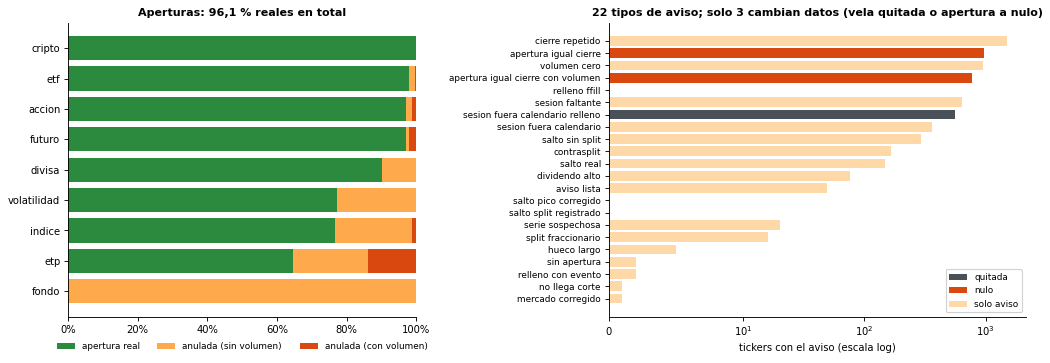

Sin ninguna apertura real: VBMFX, ^SKEW


In [11]:
an = pav[pav['tipo'].isin(['apertura_igual_cierre', 'apertura_igual_cierre_con_volumen'])].pivot_table(
    index='ticker', columns='tipo', values='n', aggfunc='sum', fill_value=0).reindex(P['ticker'], fill_value=0)
P['anul_sin'] = an['apertura_igual_cierre'].to_numpy()
P['anul_con'] = an['apertura_igual_cierre_con_volumen'].to_numpy()
assert (P['anul_sin'] + P['anul_con']).sum() == P['aperturas_anuladas'].sum()
g = P.groupby('clase')[['sesiones_despues', 'anul_sin', 'anul_con']].sum()
g['reales'] = g['sesiones_despues'] - g['anul_sin'] - g['anul_con']
pr = g[['reales', 'anul_sin', 'anul_con']].div(g['sesiones_despues'], axis=0).sort_values('reales')
av = pav.groupby(['tipo', 'accion'])['ticker'].nunique().unstack(fill_value=0)
av = av.loc[av.sum(axis=1).sort_values().index]
COL_ACC = {'quitada': '#495057', 'nulo': '#d9480f', 'solo aviso': '#ffd8a8'}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1, 1.2]})
izq = np.zeros(len(pr))
for c, etq, color in (('reales', 'apertura real', COL_OK), ('anul_sin', 'anulada (sin volumen)', '#ffa94d'),
                      ('anul_con', 'anulada (con volumen)', '#d9480f')):
    a1.barh(pr.index, pr[c], left=izq, color=color, label=etq)
    izq += pr[c].to_numpy()
a1.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
a1.set_title(f"Aperturas: {es(100 * g['reales'].sum() / g['sesiones_despues'].sum(), 1)} % reales en total", fontsize=10)
a1.legend(fontsize=8, loc='upper center', bbox_to_anchor=(.5, -.06), ncol=3, frameon=False)
izq = np.zeros(len(av))
for acc in [a for a in COL_ACC if a in av.columns]:
    a2.barh(av.index.str.replace('_', ' '), av[acc], left=izq, color=COL_ACC[acc], label=acc)
    izq += av[acc].to_numpy()
a2.set_xscale('symlog', linthresh=10)
a2.set_xlabel('tickers con el aviso (escala log)')
cambian = av[[c for c in ('quitada', 'nulo') if c in av.columns]].sum(axis=1).gt(0)
a2.set_title(f"{len(av)} tipos de aviso; solo {n(cambian)} cambian datos (vela quitada o apertura a nulo)", fontsize=10)
a2.legend(fontsize=8, loc='lower right', framealpha=.9)
a2.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.show()
print('Sin ninguna apertura real:', ', '.join(pav.loc[pav['tipo'] == 'sin_apertura', 'ticker']))

## 6. Para los agentes

**Qué se ve:** qué temas puede pedir cada tipo de agente. Es **orientativo, no una decisión** (D5: el agente de cada
dato se decide al construir los agentes): se usa el campo `agentes` del catálogo donde existe y, si no, una asignación
por tema. **El catálogo formal para los agentes** (id, descripción, agente, frecuencia, desde y fiabilidad de la fecha)
**es el paso siguiente**; esta figura solo enseña que cada agente tendrá datos. Debajo, consultas reales en modo curado en dos fechas de crisis (la quiebra de Lehman y la del COVID),
mostrando solo metadatos. **Conclusión:** cada agente tiene su núcleo de datos, y las tools explican con avisos o con un
error neutro lo que no se podía ver en esa fecha.

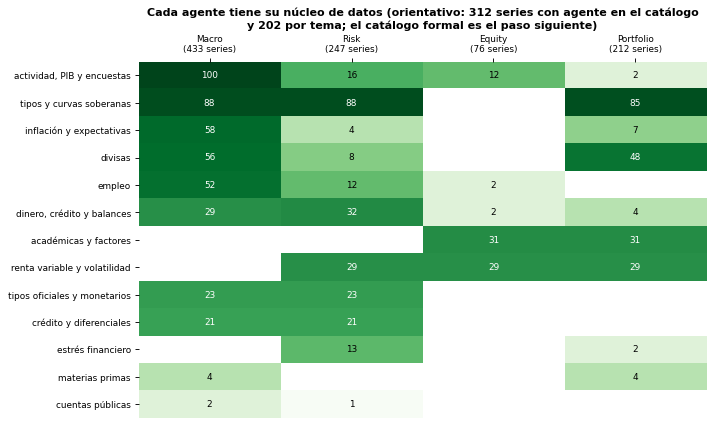

Precios por agente (orientativo): Equity, acciones 1278 · Portfolio, ETF/ETP/futuros/divisas/índices 211 · Risk, volatilidad 5


In [12]:
AG_DEF = {'tipos y curvas soberanas': ['macro', 'risk', 'portfolio'], 'tipos oficiales y monetarios': ['macro', 'risk'],
          'crédito y diferenciales': ['risk', 'macro'], 'estrés financiero': ['risk'], 'inflación y expectativas': ['macro'],
          'empleo': ['macro'], 'actividad, PIB y encuestas': ['macro'], 'cuentas públicas': ['macro'],
          'dinero, crédito y balances': ['macro', 'risk'], 'divisas': ['macro', 'portfolio'],
          'renta variable y volatilidad': ['equity', 'risk', 'portfolio'], 'materias primas': ['macro', 'portfolio'],
          'académicas y factores': ['equity', 'portfolio']}
AGENTES = ['macro', 'risk', 'equity', 'portfolio']
S['agentes'] = [CAT.get(s, {}).get('agentes') or AG_DEF[g] for s, g in zip(S['serie'], S['grupo'])]
S['de_catalogo'] = [bool(CAT.get(s, {}).get('agentes')) for s in S['serie']]
ea = S.explode('agentes')
ha = pd.crosstab(ea['grupo'], ea['agentes']).reindex(index=ORDEN_G, columns=AGENTES, fill_value=0)
fig, ax = plt.subplots(figsize=(9, 5.4))
mapa(ax, ha.to_numpy().astype(float), ha.index, [f'{a.capitalize()}\n({n(ea["agentes"] == a)} series)' for a in AGENTES],
     cmap='Greens')
ax.xaxis.tick_top()
ax.set_title(f"Cada agente tiene su núcleo de datos (orientativo: {n(S['de_catalogo'])} series con agente en el catálogo\n"
             f"y {n(~S['de_catalogo'])} por tema; el catálogo formal es el paso siguiente)", pad=30, fontsize=10)
plt.tight_layout()
plt.show()
print('Precios por agente (orientativo): Equity, acciones', n(P['clase'] == 'accion'), '· Portfolio, ETF/ETP/futuros/'
      'divisas/índices', n(P['clase'].isin(['etf', 'etp', 'futuro', 'divisa', 'indice', 'fondo', 'cripto'])),
      '· Risk, volatilidad', n(P['clase'] == 'volatilidad'))

In [13]:
CONSULTAS = [
    ('Macro', 'get_serie', 'fred:UNRATE', '2008-09-15'),
    ('Risk', 'get_serie', 'fred:VIXCLS', '2008-09-15'),
    ('Risk', 'get_serie', 'ofr:FSI', '2008-09-15'),
    ('Equity', 'get_precios', '^GSPC', '2020-03-16'),
    ('Portfolio', 'get_precios', 'SPY', '2020-03-16'),
    ('Macro', 'get_proyeccion', 'fred:UNRATEMD', '2020-03-16'),
    ('Macro', 'get_proyeccion', 'fred:UNRATEMD', str(CORTE.date())),
]
filas, avisos = [], []
for agente, f, id_, fecha in CONSULTAS:
    llamada = f"{f}('{id_}', '{fecha}'" + (", base='curada')" if f != 'get_proyeccion' else ')')
    try:
        if f == 'get_precios':
            r_ = tools.get_precios(id_, fecha, base='curada', divisa='original')
            d, col, extra = r_.datos, 'sesion', f"{n(r_.datos['open'].isna())} sesiones sin apertura"
        elif f == 'get_proyeccion':
            r_ = tools.get_proyeccion(id_, fecha)
            d, col, extra = r_.datos, 'fecha_referencia', f"ediciones {', '.join(sorted(set(r_.datos['edicion'])))}"
        else:
            r_ = tools.get_serie(id_, fecha, base='curada')
            d, col, extra = r_.datos, 'fecha_referencia', r_.unidad
        filas.append({'agente': agente, 'llamada': llamada, 'resultado': 'datos', 'filas': len(d),
                      'desde': d[col].min().date(), 'hasta': d[col].max().date(), 'detalle': extra, 'avisos': len(r_.avisos)})
        avisos += [(llamada, a) for a in r_.avisos]
    except KeyError as e:
        filas.append({'agente': agente, 'llamada': llamada, 'resultado': 'KeyError (no visible en la fecha)', 'filas': 0,
                      'desde': None, 'hasta': None, 'detalle': str(e)[:90], 'avisos': 0})
display(pd.DataFrame(filas))
for llamada, a in avisos:
    print(f'{llamada}\n   → {a[:220]}' + ('…' if len(a) > 220 else ''))

,agente,llamada,resultado,filas,desde,hasta,detalle,avisos
0,Macro,"get_serie('fred:UNRATE', '2008-09-15', base='curada')",datos,728,1948-01-01,2008-08-01,% de la población activa,1
1,Risk,"get_serie('fred:VIXCLS', '2008-09-15', base='curada')",datos,4713,1990-01-02,2008-09-12,"puntos de índice (volatilidad implícita anualizada, %)",0
2,Risk,"get_serie('ofr:FSI', '2008-09-15', base='curada')",KeyError (no visible en la fecha),0,None,None,"""serie 'ofr:FSI' sin datos publicados hasta 2008-09-15 (desconocida o aún no publicada)""",0
3,Equity,"get_precios('^GSPC', '2020-03-16', base='curada')",datos,23160,1927-12-30,2020-03-16,8547 sesiones sin apertura,1
4,Portfolio,"get_precios('SPY', '2020-03-16', base='curada')",datos,6831,1993-01-29,2020-03-16,0 sesiones sin apertura,0
5,Macro,"get_proyeccion('fred:UNRATEMD', '2020-03-16')",datos,6,2015-01-01,2020-01-01,"ediciones 2015-12-16, 2016-12-14, 2017-12-13, 2018-09-26, 2019-12-11",1
6,Macro,"get_proyeccion('fred:UNRATEMD', '2026-11-13')",datos,12,2015-01-01,2026-01-01,"ediciones 2015-12-16, 2016-12-14, 2017-12-13, 2018-09-26, 2019-12-11, 2020-12-16, 2021-12-15, 2022-12-14, ...",1


get_serie('fred:UNRATE', '2008-09-15', base='curada')
   → 27 periodos anteriores a ALFRED (primer vintage 1960-03-15): llevan el valor de ese primer vintage, ya revisado, con la fecha de la regla previa (lag_fijo): posible fuga de revisiones y fecha de publicación aproximada
get_precios('^GSPC', '2020-03-16', base='curada')
   → ^GSPC: 8547 sesiones con apertura nula (relleno del proveedor quitado en la base curada: open == close y high == low); no valen como apertura de t+1
get_proyeccion('fred:UNRATEMD', '2020-03-16')
   → fred:UNRATEMD: proyección, no un dato observado de su periodo: cada fecha_referencia lleva la última edición visible en 2020-03-16 (5 ediciones; la última, 2019-12-11)
get_proyeccion('fred:UNRATEMD', '2026-11-13')
   → fred:UNRATEMD: proyección, no un dato observado de su periodo: cada fecha_referencia lleva la última edición visible en 2026-11-13 (12 ediciones; la última, 2026-09-16)


El `KeyError` de `ofr:FSI` en 2008 no es un fallo: el índice de la OFR se creó después (fecha externa F1–F2), así que en
2008 no existía y la tool responde como si no existiera. Las proyecciones son las del SEP de la Fed (el WEO salió de la curada en el saneado,
P16, porque solo había ediciones desde 2025).

## 7. Limitaciones declaradas

**Qué se ve:** lo que el dataset no tiene o tiene a medias, con su alcance (calculado de `descargas_3b_estado.csv`, los
avisos de precios y las tools) y lo que implica para el backtest. Las filas del 3b cuentan entradas de la lista de
descargas; los avisos cuentan tickers con precios curados, por eso pueden no coincidir (se explica en cada fila). **Conclusión:** ninguna invalida el dataset, pero
varias obligan a medir su efecto (sesgo de supervivencia) o a no usar un dato antes de cierta fecha.

In [14]:
lim = est[est['estado_3b'] == 'limitacion_declarada']
nota_av = pav.loc[pav['tipo'] == 'aviso_lista', 'nota'].fillna('')
recortada = n(nota_av.str.contains('historia recortada'))
ucits_corr = n(nota_av.str.contains('correlación semanal baja'))
reutil = n(nota_av.str.contains('ticker reutilizado'))
no_corte = pav[pav['tipo'] == 'no_llega_corte']
r_cny = tools.get_precios('000001.SS', str(CORTE.date()), base='curada', divisa='USD')
sin_fx = r_cny.datos['fx_usd'].isna()
cny_nan, cny_hasta = n(sin_fx), r_cny.datos.loc[sin_fx, 'sesion'].max()
# Sospechosas: filas del 3b frente a tickers con el aviso del EDA en los precios curados
ids_sos = set(est.loc[est['tipo'] == 'serie_sospechosa', 'id'])
dif_sos = sorted(ids_sos - set(pav.loc[pav['tipo'] == 'serie_sospechosa', 'ticker']))
expl_sos = '; '.join(f"{t_}: fuera de la lista (fichero truncado), sin precios curados" if dec_p.get(t_) == 'fuera'
                     else f"{t_}: marcada sospechosa en la lista (aviso_lista), no por el EDA" for t_ in dif_sos)
ser_lim = lim[lim['tipo'] == 'series']['id'].tolist()
ed_weo = est.loc[(est['tipo'] == 'ediciones') & (est['estado_3b'] == 'hecho'), 'id'].str.split(':').str[-1].min()
pub = inv.set_index('id')['pub_desde']
al = pd.DataFrame([{'alias': k, 'canonico': v.get('alias_de')} for k, v in LISTA.items() if v['decision'] == 'alias'])
al_prev = n(pd.to_datetime(al['alias'].map(pub)) < pd.to_datetime(al['canonico'].map(pub)))
LIM = [
    ('Sesgo de supervivencia (solo Yahoo, F3)', f"{es(m5['pct_dias_tramo_cubiertos'], 1)} % de los días-tramo del S&P 500 "
     f"cubiertos; {es(m5['tramos_sin_fichero'])} tramos sin fichero",
     'las empresas que salieron y dejaron de cotizar faltan: medir el sesgo en el backtest (universo punto a punto)'),
    ('Tickers reutilizados', f"{es(m5['tickers_reutilizados'])} tickers del S&P 500; {reutil} con aviso en la lista",
     'el fichero es de otra empresa: no usarlo para el miembro antiguo'),
    ('Series sospechosas', f"{n(lim['tipo'] == 'serie_sospechosa')} filas del 3b; {n(pav['tipo'] == 'serie_sospechosa')} "
     f"tickers con el aviso del EDA (la diferencia: {expl_sos})",
     'historial roto (saltos o cierres repetidos): filtrar o vigilar en el backtest'),
    ('Ediciones del WEO', f"{n((est['tipo'] == 'ediciones') & (est['estado_3b'] == 'hecho'))} ediciones descargadas; "
     f"{n((est['tipo'] == 'ediciones') & (est['estado_3b'] == 'limitacion_declarada'))} sin fuente permitida",
     f"las proyecciones del FMI solo existen desde la edición {ed_weo}: no hay previsiones del WEO para las crisis pasadas"),
    ('Zona euro cambiante y otras series sin publicar', ', '.join(s.split(':')[1] for s in ser_lim),
     'se usa el sustituto que dice el motivo (EA20, LFSI del BCE, G4E, paro anual del Banco Mundial)'),
    ('Historia recortada de los UCITS', f'{recortada} tickers (Yahoo empieza después del lanzamiento)',
     'la cartera UCITS tiene menos historia que el ETF de EE. UU. equivalente: usar el de EE. UU. antes'),
    ('UCITS poco parecidos a su ETF de EE. UU.', f'{ucits_corr} alias UCITS con correlación semanal baja',
     'no sustituir sin más el ETF de EE. UU. por el UCITS (ni al revés)'),
    ('Ficheros que no llegan al corte', f"{len(no_corte)} tickers ({', '.join(no_corte['ticker'].head(4))}…)",
     'última sesión antes del corte: las tools avisan de datos atrasados'),
    ('Yahoo revisa sesiones guardadas', f"{n(lim['tipo'] == 'excepcion_refresco')} tickers",
     'se conserva lo guardado (la base solo crece); puede diferir de Yahoo hoy'),
    ('USD de las series en CNY', f"{cny_nan} sesiones de 000001.SS sin fixing del BCE visible (la última, "
     f"{pd.Timestamp(cny_hasta).date() if cny_nan else '—'})",
     "con divisa='USD' salen como NaN: pendiente de revisar en las tools o en el FX; mientras, divisa='original'"),
    ('Historia anterior de los alias', f'{al_prev} alias empiezan antes que su canónico',
     "esa historia solo está en la base de trabajo (base='trabajo')"),
    ('Sin fuente gratuita y legal (G1)', ', '.join(lim.loc[lim['motivo_3b'].str.startswith('G1'), 'id']),
     'vintages de BCE, Eurostat, BIS y Banco Mundial: valores de hoy con fecha conservadora'),
    ('Otras', ', '.join(sorted(set(lim['tipo']) - {'serie_sospechosa', 'ediciones', 'series', 'excepcion_refresco'})),
     'ver motivo_3b en descargas_3b_estado.csv'),
]
pd.DataFrame(LIM, columns=['limitación', 'alcance', 'qué implica para el backtest']).style.hide(axis='index')

limitación,alcance,qué implica para el backtest
"Sesgo de supervivencia (solo Yahoo, F3)","67,8 % de los días-tramo del S&P 500 cubiertos; 459 tramos sin fichero",las empresas que salieron y dejaron de cotizar faltan: medir el sesgo en el backtest (universo punto a punto)
Tickers reutilizados,112 tickers del S&P 500; 0 con aviso en la lista,el fichero es de otra empresa: no usarlo para el miembro antiguo
Series sospechosas,"37 filas del 3b; 20 tickers con el aviso del EDA (la diferencia: ABI: fuera de la lista (fichero truncado), sin precios curados; ABTC.SW: fuera de la lista (fichero truncado), sin precios curados; AETH.SW: fuera de la lista (fichero truncado), sin precios curados; BAY: fuera de la lista (fichero truncado), sin precios curados; BLY: fuera de la lista (fichero truncado), sin precios curados; COMS: fuera de la lista (fichero truncado), sin precios curados; DIGI: fuera de la lista (fichero truncado), sin precios curados; DWD: fuera de la lista (fichero truncado), sin precios curados; GR: fuera de la lista (fichero truncado), sin precios curados; IBTS.L: marcada sospechosa en la lista (aviso_lista), no por el EDA; MI: fuera de la lista (fichero truncado), sin precios curados; PCL: fuera de la lista (fichero truncado), sin precios curados; PCS: fuera de la lista (fichero truncado), sin precios curados; PWER: fuera de la lista (fichero truncado), sin precios curados; SBNY: fuera de la lista (fichero truncado), sin precios curados; UN: fuera de la lista (fichero truncado), sin precios curados; USBC: fuera de la lista (fichero truncado), sin precios curados)",historial roto (saltos o cierres repetidos): filtrar o vigilar en el backtest
Ediciones del WEO,3 ediciones descargadas; 34 sin fuente permitida,las proyecciones del FMI solo existen desde la edición 2025-04: no hay previsiones del WEO para las crisis pasadas
Zona euro cambiante y otras series sin publicar,"ei_bssi_m_r2.EA, une_rt_m.EA, LI_AA.EA20, UNEMP.CHN, EMPLOY, PCPI, RUC","se usa el sustituto que dice el motivo (EA20, LFSI del BCE, G4E, paro anual del Banco Mundial)"
Historia recortada de los UCITS,18 tickers (Yahoo empieza después del lanzamiento),la cartera UCITS tiene menos historia que el ETF de EE. UU. equivalente: usar el de EE. UU. antes
UCITS poco parecidos a su ETF de EE. UU.,23 alias UCITS con correlación semanal baja,no sustituir sin más el ETF de EE. UU. por el UCITS (ni al revés)
Ficheros que no llegan al corte,1 tickers (PARA…),última sesión antes del corte: las tools avisan de datos atrasados
Yahoo revisa sesiones guardadas,24 tickers,se conserva lo guardado (la base solo crece); puede diferir de Yahoo hoy
USD de las series en CNY,"0 sesiones de 000001.SS sin fixing del BCE visible (la última, —)","con divisa='USD' salen como NaN: pendiente de revisar en las tools o en el FX; mientras, divisa='original'"


## 8. Cómo reproducirlo

**Qué se ve:** las órdenes, en orden, que rehacen el dataset desde cero (`python -m ingesta.mercados_series <orden>`),
y el manifiesto que ata la base curada a lo que la produjo. **Conclusión:** todo sale de órdenes reanudables y
deterministas; el manifiesto permite comprobar que la base curada corresponde a los YAML de hoy.

1. **Descargas** (reanudables; las largas, en segundo plano): `descargar-alfred`, `descargar-fred-vivo`,
   `descargar-<fuente>` (bce, eurostat, bis, imf, worldbank, oecd, philly, bancos, curvas, cripto),
   `descargar-precios --nivel nucleo|ampliado` y `archivar-oas` (cada mes).
2. **`construir-base`**: une las fuentes en `series/base_series.parquet` (la base de trabajo; solo crece).
3. **Paso 2**: `inventario` y `redundancia`.
4. **Paso 3**: `eda`, `seleccion` (escribe `config/lista_curada.yaml`) y `preprocesado` (simula el plan de
   `config/preprocesado.yaml`).
5. **Paso 4**: `curar` (base curada, alias, proyecciones, registro de cambios y manifiesto) y `curar-precios`.
6. **Estado del 3b**: `estado_3b` (`tablas/descargas_3b_estado.csv`).

In [15]:
def sha(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()


filas = []
for nombre, e in MAN['entradas'].items():
    ruta = Path(e['ruta'])
    if ruta.suffix == '.yaml':
        igual = sha(ruta) == e['sha256']
    else:
        st = ruta.stat()
        igual = st.st_size == e['tamano'] and st.st_mtime_ns == e['mtime_ns']
    filas.append({'tipo': 'entrada', 'nombre': nombre, 'fichero': ruta.name, 'tamaño_MB': round(e['tamano'] / 1e6, 2),
                  'filas': np.nan, 'sha256': e['sha256'][:12] + '…', 'igual_hoy': igual})
for nombre, e in MAN['salidas'].items():
    filas.append({'tipo': 'salida', 'nombre': nombre, 'fichero': e['fichero'], 'tamaño_MB': round(e['tamano'] / 1e6, 2),
                  'filas': e['filas'], 'sha256': e['sha256'][:12] + '…', 'igual_hoy': np.nan})
print(f"Manifiesto creado {MAN['creado_utc']} · corte G2 {MAN['corte_g2']} · construcción en {es(R['segundos'])} s · "
      f"verificaciones con fallos: {sum(v != 0 for v in MAN['verificaciones'].values())} de {len(MAN['verificaciones'])}")
pd.DataFrame(filas)

Manifiesto creado 2026-11-21T15:35:41+00:00 · corte G2 2026-11-13 · construcción en 257 s · verificaciones con fallos: 0 de 13


,tipo,nombre,fichero,tamaño_MB,filas,sha256,igual_hoy
0,entrada,base_series,base_series.parquet,97.39,NaN,9221bb9b1a84…,True
1,entrada,lista_curada,lista_curada.yaml,0.70,NaN,ad767b09ca80…,False
2,entrada,preprocesado,preprocesado.yaml,0.08,NaN,7cea58a0b34e…,True
3,salida,base_curada,base_curada.parquet,88.27,10212510.0,1081a21c6fc3…,NaN
4,salida,alias,alias.parquet,0.01,59.0,4990b115d7a4…,NaN
5,salida,proyecciones,proyecciones.parquet,0.01,116.0,87049afc6094…,NaN
6,salida,registro_cambios,registro_cambios.parquet,17.32,1492997.0,02c1bcbf385a…,NaN
